Step 10.1 — Load the Selected Model and Final Test Data

In [2]:

# ============================================================
# PHASE 10 — STEP 10.1: LOAD SELECTED MODEL AND FINAL TEST DATA
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

# Project paths
PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Phase 9 selected Class-Weighted XGBoost
MODEL_PATH = MODEL_DIR / "phase9_selected_xgboost_candidate.pkl"

# Original final test data
X_test = pd.read_csv(DATA_DIR / "X_test_encoded.csv")
y_test = np.load(DATA_DIR / "y_test_encoded.npy")

# Load the saved model and preprocessing objects
weighted_model = joblib.load(MODEL_PATH)
scaler = joblib.load(DATA_DIR / "scaler.pkl")
target_encoder = joblib.load(DATA_DIR / "target_encoder.pkl")

# Basic integrity checks
assert MODEL_PATH.exists(), f"Model file not found: {MODEL_PATH}"
assert len(X_test) == len(y_test), "X_test and y_test sample counts do not match."
assert X_test.shape[1] == 41, f"Expected 41 features, found {X_test.shape[1]}"
assert not X_test.isnull().any().any(), "Missing values found in X_test."
assert np.isfinite(X_test.to_numpy(dtype=float)).all(), "Infinite values found."

print("=" * 65)
print("PHASE 10 — STEP 10.1: DATA AND MODEL LOADED")
print("=" * 65)
print(f"Selected model : {MODEL_PATH.name}")
print(f"Test samples   : {len(X_test):,}")
print(f"Test features  : {X_test.shape[1]}")
print(f"Test classes   : {len(np.unique(y_test))}")
print(f"Model classes  : {len(weighted_model.classes_)}")
print("Missing values :", X_test.isnull().sum().sum())
print("Test data loaded successfully.")


PHASE 10 — STEP 10.1: DATA AND MODEL LOADED
Selected model : phase9_selected_xgboost_candidate.pkl
Test samples   : 29,696
Test features  : 41
Test classes   : 28
Model classes  : 28
Missing values : 0
Test data loaded successfully.


Step 10.2 — Evaluate the Selected Model

In [9]:

# ============================================================
# PHASE 10 — STEP 10.2: FINAL TEST EVALUATION
# Selected Class-Weighted XGBoost
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

print("=" * 75)
print("PHASE 10 — STEP 10.2: FINAL TEST EVALUATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = (
    MODEL_DIR / "phase9_selected_xgboost_candidate.pkl"
)

X_TEST_PATH = DATA_DIR / "X_test_encoded.csv"
Y_TEST_PATH = DATA_DIR / "y_test_encoded.npy"
TARGET_ENCODER_PATH = DATA_DIR / "target_encoder.pkl"

# ------------------------------------------------------------
# 2. CHECK REQUIRED FILES
# ------------------------------------------------------------

required_files = [
    MODEL_PATH,
    X_TEST_PATH,
    Y_TEST_PATH,
    TARGET_ENCODER_PATH
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing_files)
    )

print("\nAll required files were found.")

# ------------------------------------------------------------
# 3. LOAD MODEL AND TEST DATA
# ------------------------------------------------------------

weighted_model = joblib.load(MODEL_PATH)

X_test = pd.read_csv(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH)

target_encoder = joblib.load(TARGET_ENCODER_PATH)

print("\nModel and test data loaded successfully.")

# ------------------------------------------------------------
# 4. VALIDATE DATA
# ------------------------------------------------------------

assert len(X_test) == len(y_test), (
    "X_test and y_test have different sample counts."
)

assert X_test.shape[1] == 41, (
    f"Expected 41 features, found {X_test.shape[1]}."
)

assert not X_test.isnull().any().any(), (
    "Missing values were found in X_test."
)

assert np.isfinite(
    X_test.to_numpy(dtype=float)
).all(), (
    "Infinite or non-numeric feature values were found."
)

class_names = target_encoder.classes_.tolist()
class_labels = np.arange(len(class_names))

assert set(np.unique(y_test)).issubset(
    set(class_labels)
), "Test labels do not match the target encoder."

assert X_test.shape[1] == weighted_model.n_features_in_, (
    "Test feature count does not match the model's expected "
    "feature count."
)

print("\nDATA VALIDATION")
print("-" * 50)
print(f"Test samples       : {len(X_test):,}")
print(f"Test features      : {X_test.shape[1]}")
print(f"Target classes     : {len(class_names)}")
print(f"Model expected features: {weighted_model.n_features_in_}")
print(f"Missing values     : {X_test.isnull().sum().sum()}")

# ------------------------------------------------------------
# 5. GENERATE PREDICTIONS
#
# IMPORTANT:
# Phase 9 weighted model was trained on unscaled encoded
# features. Therefore, use X_test directly.
# Do not use scaler.transform(X_test) for this model.
# ------------------------------------------------------------

print("\nGenerating predictions...", flush=True)

y_pred_weighted = weighted_model.predict(X_test)

y_pred_weighted = np.asarray(
    y_pred_weighted
).reshape(-1)

assert len(y_pred_weighted) == len(y_test), (
    "Prediction count does not match test sample count."
)

print("Predictions generated successfully.")

# ------------------------------------------------------------
# 6. CALCULATE OVERALL METRICS
# ------------------------------------------------------------

metrics = {
    "phase": 10,
    "step": "10.2",
    "model": "Class-Weighted XGBoost",
    "test_samples": int(len(y_test)),
    "test_features": int(X_test.shape[1]),
    "classes_evaluated": int(len(class_names)),

    "accuracy": float(
        accuracy_score(y_test, y_pred_weighted)
    ),

    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred_weighted)
    ),

    "macro_precision": float(
        precision_score(
            y_test,
            y_pred_weighted,
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    ),

    "macro_recall": float(
        recall_score(
            y_test,
            y_pred_weighted,
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    ),

    "macro_f1": float(
        f1_score(
            y_test,
            y_pred_weighted,
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    ),

    "weighted_f1": float(
        f1_score(
            y_test,
            y_pred_weighted,
            labels=class_labels,
            average="weighted",
            zero_division=0
        )
    ),

    "mcc": float(
        matthews_corrcoef(y_test, y_pred_weighted)
    ),

    "cohen_kappa": float(
        cohen_kappa_score(y_test, y_pred_weighted)
    ),

    "correct_predictions": int(
        np.sum(y_test == y_pred_weighted)
    ),

    "incorrect_predictions": int(
        np.sum(y_test != y_pred_weighted)
    )
}

# ------------------------------------------------------------
# 7. DISPLAY OVERALL METRICS
# ------------------------------------------------------------

percentage_metrics = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1"
]

print("\n" + "=" * 75)
print("STEP 10.2 — OVERALL TEST METRICS")
print("=" * 75)

for key, value in metrics.items():

    if key in percentage_metrics:
        print(
            f"{key:<25}: "
            f"{value:.6f} ({value * 100:.2f}%)"
        )

    elif isinstance(value, int):
        print(f"{key:<25}: {value:,}")

    elif isinstance(value, float):
        print(f"{key:<25}: {value:.6f}")

    else:
        print(f"{key:<25}: {value}")

# ------------------------------------------------------------
# 8. GENERATE CLASSIFICATION REPORT
# ------------------------------------------------------------

report_dict = classification_report(
    y_test,
    y_pred_weighted,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_test,
    y_pred_weighted,
    labels=class_labels,
    target_names=class_names,
    zero_division=0
)

class_report_df = pd.DataFrame(report_dict).transpose()

print("\n" + "=" * 75)
print("STEP 10.2 — CLASS-WISE CLASSIFICATION REPORT")
print("=" * 75)

print(report_text)

# ------------------------------------------------------------
# 9. GENERATE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred_weighted,
    labels=class_labels
)

confusion_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

confusion_df.index.name = "Actual"
confusion_df.columns.name = "Predicted"

print("\nConfusion matrix generated.")
print(f"Confusion matrix shape: {cm.shape}")

# ------------------------------------------------------------
# 10. SAVE METRICS, REPORT AND PREDICTIONS
# ------------------------------------------------------------

metrics_path = (
    RESULTS_DIR / "phase10_weighted_xgboost_metrics.json"
)

class_report_path = (
    RESULTS_DIR
    / "phase10_weighted_xgboost_classification_report.csv"
)

confusion_path = (
    RESULTS_DIR
    / "phase10_weighted_xgboost_confusion_matrix.csv"
)

predictions_path = (
    RESULTS_DIR
    / "phase10_weighted_xgboost_predictions.csv"
)

text_report_path = (
    REPORTS_DIR / "phase10_weighted_xgboost_report.txt"
)

# Save overall metrics
with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

# Save per-class metrics
class_report_df.to_csv(
    class_report_path,
    index=True
)

# Save confusion matrix
confusion_df.to_csv(confusion_path)

# Save actual and predicted labels
predictions_df = pd.DataFrame({
    "actual_encoded": y_test,
    "predicted_encoded": y_pred_weighted,
    "correct_prediction": (
        y_test == y_pred_weighted
    )
})

predictions_df.to_csv(
    predictions_path,
    index=False
)

# Save readable text report
with open(
    text_report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "PHASE 10 — STEP 10.2: FINAL TEST EVALUATION\n"
    )
    file.write("=" * 65 + "\n\n")

    file.write(
        "Model: Class-Weighted XGBoost\n"
    )

    file.write(
        "Prediction input: Unscaled encoded test features\n\n"
    )

    file.write("OVERALL METRICS\n")
    file.write("-" * 40 + "\n")

    for key, value in metrics.items():
        file.write(f"{key}: {value}\n")

    file.write("\nCLASSIFICATION REPORT\n")
    file.write("-" * 40 + "\n")
    file.write(report_text)

# ------------------------------------------------------------
# 11. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 10.2 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nSaved files:")

for path in [
    metrics_path,
    class_report_path,
    confusion_path,
    predictions_path,
    text_report_path
]:
    print(f"- {path}")

print("\nImportant interpretation:")
print(
    "These results evaluate the selected Phase 9 model "
    "on the existing test set."
)
print(
    "The test set was already evaluated in Phase 8, "
    "so this is not a completely untouched test evaluation."
)

print("\nNext step: Review the output before running Step 10.3.")


PHASE 10 — STEP 10.2: FINAL TEST EVALUATION

All required files were found.

Model and test data loaded successfully.

DATA VALIDATION
--------------------------------------------------
Test samples       : 29,696
Test features      : 41
Target classes     : 28
Model expected features: 41
Missing values     : 0

Generating predictions...
Predictions generated successfully.

STEP 10.2 — OVERALL TEST METRICS
phase                    : 10
step                     : 10.2
model                    : Class-Weighted XGBoost
test_samples             : 29,696
test_features            : 41
classes_evaluated        : 28
accuracy                 : 0.996397 (99.64%)
balanced_accuracy        : 0.865237 (86.52%)
macro_precision          : 0.824740 (82.47%)
macro_recall             : 0.865237 (86.52%)
macro_f1                 : 0.834588 (83.46%)
weighted_f1              : 0.996515 (99.65%)
mcc                      : 0.994134
cohen_kappa              : 0.994131
correct_predictions      : 29,589
incorrec

Phase 10 — Step 10.3: Old vs New Model Comparison

In [13]:

# ============================================================
# PHASE 10 — STEP 10.3: OLD VS NEW MODEL COMPARISON
# Original XGBoost vs Class-Weighted XGBoost
# ============================================================

import json
import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report
)

print("=" * 75)
print("PHASE 10 — STEP 10.3: OLD VS NEW MODEL COMPARISON")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

OLD_MODEL_PATH = MODEL_DIR / "final_xgboost_model.pkl"
NEW_MODEL_PATH = MODEL_DIR / "phase9_selected_xgboost_candidate.pkl"

X_TEST_PATH = DATA_DIR / "X_test_encoded.csv"
Y_TEST_PATH = DATA_DIR / "y_test_encoded.npy"
SCALER_PATH = DATA_DIR / "scaler.pkl"
TARGET_ENCODER_PATH = DATA_DIR / "target_encoder.pkl"

# ------------------------------------------------------------
# 2. CHECK REQUIRED FILES
# ------------------------------------------------------------

required_files = [
    OLD_MODEL_PATH,
    NEW_MODEL_PATH,
    X_TEST_PATH,
    Y_TEST_PATH,
    SCALER_PATH,
    TARGET_ENCODER_PATH
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following files are missing:\n"
        + "\n".join(missing_files)
    )

print("\nAll required files were found.")

# ------------------------------------------------------------
# 3. LOAD MODELS AND DATA
# ------------------------------------------------------------

old_model = joblib.load(OLD_MODEL_PATH)
new_model = joblib.load(NEW_MODEL_PATH)

X_test = pd.read_csv(X_TEST_PATH)
y_test = np.load(Y_TEST_PATH)

scaler = joblib.load(SCALER_PATH)
target_encoder = joblib.load(TARGET_ENCODER_PATH)

class_names = target_encoder.classes_.tolist()
class_labels = np.arange(len(class_names))

print("Both models and test data loaded successfully.")

# ------------------------------------------------------------
# 4. VALIDATE TEST DATA
# ------------------------------------------------------------

assert len(X_test) == len(y_test), (
    "X_test and y_test sample counts do not match."
)

assert X_test.shape[1] == 41, (
    f"Expected 41 features, found {X_test.shape[1]}."
)

assert X_test.isnull().sum().sum() == 0, (
    "Missing values were found in X_test."
)

assert np.isfinite(
    X_test.to_numpy(dtype=float)
).all(), (
    "Test data contains infinite or invalid numeric values."
)

assert set(np.unique(y_test)).issubset(
    set(class_labels)
), "Test labels do not match the target encoder."

assert X_test.shape[1] == old_model.n_features_in_, (
    "Original model feature count mismatch."
)

assert X_test.shape[1] == new_model.n_features_in_, (
    "Weighted model feature count mismatch."
)

print("\nDATA VALIDATION")
print("-" * 55)
print(f"Test samples       : {len(X_test):,}")
print(f"Test features      : {X_test.shape[1]}")
print(f"Number of classes  : {len(class_names)}")
print("Missing values     : 0")

# ------------------------------------------------------------
# 5. APPLY MODEL-SPECIFIC PREPROCESSING
#
# Original XGBoost:
# Use scaled features, provided its training pipeline used
# the saved scaler.
#
# Class-Weighted XGBoost:
# Phase 9 training used unscaled encoded features.
# Therefore, pass X_test directly to the weighted model.
#
# Never fit a new scaler on the test data.
# ------------------------------------------------------------

X_test_scaled = scaler.transform(X_test)

print("\nPreprocessing prepared:")
print("Original XGBoost   : scaled encoded features")
print("Weighted XGBoost   : unscaled encoded features")

# ------------------------------------------------------------
# 6. GENERATE PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating predictions...", flush=True)

y_pred_old = np.asarray(
    old_model.predict(X_test_scaled)
).reshape(-1)

y_pred_new = np.asarray(
    new_model.predict(X_test)
).reshape(-1)

assert len(y_pred_old) == len(y_test), (
    "Original model prediction count mismatch."
)

assert len(y_pred_new) == len(y_test), (
    "Weighted model prediction count mismatch."
)

print("Original XGBoost predictions completed.")
print("Class-Weighted XGBoost predictions completed.")

# ------------------------------------------------------------
# 7. DEFINE METRIC CALCULATION FUNCTION
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred, model_name):

    return {
        "model": model_name,

        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),

        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=class_labels,
                average="macro",
                zero_division=0
            )
        ),

        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=class_labels,
                average="macro",
                zero_division=0
            )
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=class_labels,
                average="macro",
                zero_division=0
            )
        ),

        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=class_labels,
                average="weighted",
                zero_division=0
            )
        ),

        "mcc": float(
            matthews_corrcoef(y_true, y_pred)
        ),

        "cohen_kappa": float(
            cohen_kappa_score(y_true, y_pred)
        ),

        "correct_predictions": int(
            np.sum(y_true == y_pred)
        ),

        "incorrect_predictions": int(
            np.sum(y_true != y_pred)
        )
    }

# ------------------------------------------------------------
# 8. CALCULATE OVERALL MODEL METRICS
# ------------------------------------------------------------

old_metrics = calculate_metrics(
    y_test,
    y_pred_old,
    "Original XGBoost"
)

new_metrics = calculate_metrics(
    y_test,
    y_pred_new,
    "Class-Weighted XGBoost"
)

comparison_df = pd.DataFrame([
    old_metrics,
    new_metrics
])

print("\n" + "=" * 75)
print("OLD VS NEW MODEL — OVERALL COMPARISON")
print("=" * 75)

print(comparison_df.round(6).to_string(index=False))

# ------------------------------------------------------------
# 9. COMPARE CLASS-WISE PERFORMANCE
# ------------------------------------------------------------

old_report = classification_report(
    y_test,
    y_pred_old,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

new_report = classification_report(
    y_test,
    y_pred_new,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_rows = []

for class_name in class_names:

    old_values = old_report[class_name]
    new_values = new_report[class_name]

    per_class_rows.append({
        "class": class_name,

        "support": int(
            old_values["support"]
        ),

        "old_precision": float(
            old_values["precision"]
        ),

        "new_precision": float(
            new_values["precision"]
        ),

        "old_recall": float(
            old_values["recall"]
        ),

        "new_recall": float(
            new_values["recall"]
        ),

        "old_f1": float(
            old_values["f1-score"]
        ),

        "new_f1": float(
            new_values["f1-score"]
        ),

        "f1_change": float(
            new_values["f1-score"]
            - old_values["f1-score"]
        )
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n" + "=" * 75)
print("CLASS-WISE MODEL COMPARISON")
print("=" * 75)

print(per_class_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 10. DISPLAY RARE-CLASS COMPARISON
# ------------------------------------------------------------

rare_classes = [
    "ftp_write",
    "multihop",
    "rootkit",
    "loadmodule",
    "saint",
    "snmpgetattack",
    "land",
    "warezmaster",
    "imap",
    "buffer_overflow"
]

rare_results = per_class_df[
    per_class_df["class"].isin(rare_classes)
].copy()

print("\n" + "=" * 75)
print("RARE-CLASS PERFORMANCE COMPARISON")
print("=" * 75)

if not rare_results.empty:
    print(
        rare_results.round(4).to_string(index=False)
    )
else:
    print("No matching rare classes were found.")

# ------------------------------------------------------------
# 11. CALCULATE METRIC CHANGES
# Positive values mean the weighted model scored higher.
# ------------------------------------------------------------

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "mcc",
    "cohen_kappa"
]

old_row = comparison_df.iloc[0]
new_row = comparison_df.iloc[1]

metric_changes = []

for metric_name in metric_columns:

    old_value = float(old_row[metric_name])
    new_value = float(new_row[metric_name])

    metric_changes.append({
        "metric": metric_name,
        "original_xgboost": old_value,
        "class_weighted_xgboost": new_value,
        "change": new_value - old_value
    })

metric_changes_df = pd.DataFrame(metric_changes)

print("\n" + "=" * 75)
print("METRIC CHANGES: WEIGHTED MINUS ORIGINAL")
print("=" * 75)

print(metric_changes_df.round(6).to_string(index=False))

# ------------------------------------------------------------
# 12. SAVE COMPARISON RESULTS
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "phase10_old_vs_new_model_comparison.csv"
)

per_class_path = (
    RESULTS_DIR / "phase10_old_vs_new_per_class_comparison.csv"
)

rare_path = (
    RESULTS_DIR / "phase10_old_vs_new_rare_class_comparison.csv"
)

changes_path = (
    RESULTS_DIR / "phase10_old_vs_new_metric_changes.csv"
)

json_path = (
    RESULTS_DIR / "phase10_old_vs_new_model_comparison.json"
)

predictions_path = (
    RESULTS_DIR / "phase10_old_vs_new_predictions.csv"
)

report_path = (
    REPORTS_DIR / "phase10_old_vs_new_model_comparison.txt"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

rare_results.to_csv(
    rare_path,
    index=False
)

metric_changes_df.to_csv(
    changes_path,
    index=False
)

with open(
    json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        {
            "evaluation_note": (
                "The test set was previously evaluated in Phase 8. "
                "This is a repeated evaluation, not a completely "
                "untouched test evaluation."
            ),
            "original_xgboost": old_metrics,
            "class_weighted_xgboost": new_metrics,
            "metric_changes": metric_changes
        },
        file,
        indent=4
    )

predictions_df = pd.DataFrame({
    "actual_encoded": y_test,
    "original_prediction": y_pred_old,
    "weighted_prediction": y_pred_new,
    "original_correct": y_test == y_pred_old,
    "weighted_correct": y_test == y_pred_new
})

predictions_df.to_csv(
    predictions_path,
    index=False
)

# ------------------------------------------------------------
# 13. WRITE HUMAN-READABLE REPORT
# ------------------------------------------------------------

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "PHASE 10 — STEP 10.3: OLD VS NEW MODEL COMPARISON\n"
    )

    file.write("=" * 70 + "\n\n")

    file.write(
        "Original model: Original XGBoost\n"
        "Weighted model: Class-Weighted XGBoost\n"
        "Test samples: " + str(len(y_test)) + "\n"
        "Number of classes: " + str(len(class_names)) + "\n\n"
    )

    file.write("OVERALL METRICS\n")
    file.write("-" * 50 + "\n")
    file.write(
        comparison_df.to_string(index=False)
    )

    file.write("\n\nMETRIC CHANGES\n")
    file.write("-" * 50 + "\n")
    file.write(
        metric_changes_df.to_string(index=False)
    )

    file.write("\n\nCLASS-WISE COMPARISON\n")
    file.write("-" * 50 + "\n")
    file.write(
        per_class_df.to_string(index=False)
    )

    file.write("\n\nRARE-CLASS COMPARISON\n")
    file.write("-" * 50 + "\n")
    file.write(
        rare_results.to_string(index=False)
    )

    file.write(
        "\n\nPREPROCESSING NOTES\n"
        "- Original XGBoost received scaled encoded features.\n"
        "- Class-Weighted XGBoost received unscaled encoded features.\n"
        "- The test set was previously evaluated in Phase 8.\n"
        "- These results are a repeated evaluation of that test set.\n"
    )

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 10.3 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nSaved files:")

for path in [
    comparison_path,
    per_class_path,
    rare_path,
    changes_path,
    json_path,
    predictions_path,
    report_path
]:
    print(path)

print("\nKey comparison:")

print(
    f"Original XGBoost macro F1: "
    f"{old_metrics['macro_f1']:.4f}"
)

print(
    f"Class-Weighted XGBoost macro F1: "
    f"{new_metrics['macro_f1']:.4f}"
)

print(
    f"Original XGBoost balanced accuracy: "
    f"{old_metrics['balanced_accuracy']:.4f}"
)

print(
    f"Class-Weighted XGBoost balanced accuracy: "
    f"{new_metrics['balanced_accuracy']:.4f}"
)

print(
    "\nInterpret the comparison using macro F1, balanced accuracy, "
    "rare-class recall, and overall accuracy together."
)


PHASE 10 — STEP 10.3: OLD VS NEW MODEL COMPARISON

All required files were found.
Both models and test data loaded successfully.

DATA VALIDATION
-------------------------------------------------------
Test samples       : 29,696
Test features      : 41
Number of classes  : 28
Missing values     : 0

Preprocessing prepared:
Original XGBoost   : scaled encoded features
Weighted XGBoost   : unscaled encoded features

Generating predictions...
Original XGBoost predictions completed.
Class-Weighted XGBoost predictions completed.

OLD VS NEW MODEL — OVERALL COMPARISON
                 model  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  weighted_f1      mcc  cohen_kappa  correct_predictions  incorrect_predictions
      Original XGBoost  0.997542           0.840815         0.844194      0.840815  0.836976     0.997449 0.995989     0.995989                29623                     73
Class-Weighted XGBoost  0.996397           0.865237         0.824740      0.865237  0.

Step 10.4 — Model Consistency Audit

In [14]:

# ============================================================
# PHASE 10 — STEP 10.4: MODEL CONSISTENCY AND RESULTS AUDIT
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 75)
print("PHASE 10 — STEP 10.4: MODEL CONSISTENCY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

STEP_102_METRICS_PATH = (
    RESULTS_DIR / "phase10_weighted_xgboost_metrics.json"
)

STEP_102_PREDICTIONS_PATH = (
    RESULTS_DIR / "phase10_weighted_xgboost_predictions.csv"
)

STEP_103_COMPARISON_PATH = (
    RESULTS_DIR / "phase10_old_vs_new_model_comparison.csv"
)

STEP_103_PREDICTIONS_PATH = (
    RESULTS_DIR / "phase10_old_vs_new_predictions.csv"
)

STEP_103_CLASSWISE_PATH = (
    RESULTS_DIR / "phase10_old_vs_new_per_class_comparison.csv"
)

required_files = [
    STEP_102_METRICS_PATH,
    STEP_102_PREDICTIONS_PATH,
    STEP_103_COMPARISON_PATH,
    STEP_103_PREDICTIONS_PATH,
    STEP_103_CLASSWISE_PATH
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required Step 10.2 or Step 10.3 files are missing:\n"
        + "\n".join(missing_files)
    )

print("\nAll audit input files were found.")

# ------------------------------------------------------------
# 2. LOAD SAVED RESULTS
# ------------------------------------------------------------

with open(
    STEP_102_METRICS_PATH,
    "r",
    encoding="utf-8"
) as file:
    step102_metrics = json.load(file)

step102_predictions = pd.read_csv(
    STEP_102_PREDICTIONS_PATH
)

step103_comparison = pd.read_csv(
    STEP_103_COMPARISON_PATH
)

step103_predictions = pd.read_csv(
    STEP_103_PREDICTIONS_PATH
)

step103_classwise = pd.read_csv(
    STEP_103_CLASSWISE_PATH
)

print("Saved results loaded successfully.")

# ------------------------------------------------------------
# 3. CHECK ROW COUNTS
# ------------------------------------------------------------

n_step102 = len(step102_predictions)
n_step103 = len(step103_predictions)

row_count_match = n_step102 == n_step103

print("\nROW COUNT CHECK")
print("-" * 50)
print(f"Step 10.2 prediction rows: {n_step102:,}")
print(f"Step 10.3 prediction rows: {n_step103:,}")
print(f"Row counts match         : {row_count_match}")

if not row_count_match:
    raise ValueError(
        "Prediction files have different row counts. "
        "Check the saved files before continuing."
    )

# ------------------------------------------------------------
# 4. CHECK ACTUAL LABELS AND ROW ORDER
# ------------------------------------------------------------

actual_labels_match = np.array_equal(
    step102_predictions["actual_encoded"].to_numpy(),
    step103_predictions["actual_encoded"].to_numpy()
)

weighted_predictions_match = np.array_equal(
    step102_predictions["predicted_encoded"].to_numpy(),
    step103_predictions["weighted_prediction"].to_numpy()
)

step102_correct = (
    step102_predictions["actual_encoded"].to_numpy()
    == step102_predictions["predicted_encoded"].to_numpy()
)

step103_weighted_correct = (
    step103_predictions["actual_encoded"].to_numpy()
    == step103_predictions["weighted_prediction"].to_numpy()
)

correctness_flags_match = np.array_equal(
    step102_predictions["correct_prediction"].astype(bool).to_numpy(),
    step103_predictions["weighted_correct"].astype(bool).to_numpy()
)

actual_and_predictions_match = (
    actual_labels_match and weighted_predictions_match
)

print("\nPREDICTION CONSISTENCY CHECK")
print("-" * 50)
print(f"Actual labels match         : {actual_labels_match}")
print(f"Weighted predictions match  : {weighted_predictions_match}")
print(f"Correctness flags match     : {correctness_flags_match}")

# ------------------------------------------------------------
# 5. RECOMPUTE METRICS FROM SAVED PREDICTIONS
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

y_true = step102_predictions["actual_encoded"].to_numpy()
y_pred = step102_predictions["predicted_encoded"].to_numpy()

y_true_103 = (
    step103_predictions["actual_encoded"].to_numpy()
)

y_pred_103 = (
    step103_predictions["weighted_prediction"].to_numpy()
)

# Use the union of labels present in the true and predicted values.
# This ensures that predicted-only labels are also included.
all_labels = np.unique(
    np.concatenate([y_true, y_pred])
)

recomputed_metrics = {
    "accuracy": float(
        accuracy_score(y_true, y_pred)
    ),

    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),

    "macro_precision": float(
        precision_score(
            y_true,
            y_pred,
            labels=all_labels,
            average="macro",
            zero_division=0
        )
    ),

    "macro_recall": float(
        recall_score(
            y_true,
            y_pred,
            labels=all_labels,
            average="macro",
            zero_division=0
        )
    ),

    "macro_f1": float(
        f1_score(
            y_true,
            y_pred,
            labels=all_labels,
            average="macro",
            zero_division=0
        )
    ),

    "weighted_f1": float(
        f1_score(
            y_true,
            y_pred,
            labels=all_labels,
            average="weighted",
            zero_division=0
        )
    ),

    "mcc": float(
        matthews_corrcoef(y_true, y_pred)
    ),

    "cohen_kappa": float(
        cohen_kappa_score(y_true, y_pred)
    ),

    "correct_predictions": int(
        np.sum(y_true == y_pred)
    ),

    "incorrect_predictions": int(
        np.sum(y_true != y_pred)
    )
}

# ------------------------------------------------------------
# 6. COMPARE SAVED AND RECOMPUTED METRICS
# ------------------------------------------------------------

metric_rows = []

for metric_name, recomputed_value in recomputed_metrics.items():

    saved_value = step102_metrics.get(metric_name)

    if saved_value is None:
        metric_rows.append({
            "metric": metric_name,
            "step102_saved": None,
            "recomputed_from_predictions": recomputed_value,
            "absolute_difference": None,
            "match": False
        })
        continue

    difference = abs(
        float(saved_value) - float(recomputed_value)
    )

    metric_rows.append({
        "metric": metric_name,
        "step102_saved": float(saved_value),
        "recomputed_from_predictions": float(recomputed_value),
        "absolute_difference": difference,
        "match": bool(
            np.isclose(
                float(saved_value),
                float(recomputed_value),
                atol=1e-10,
                rtol=1e-8
            )
        )
    })

metrics_audit_df = pd.DataFrame(metric_rows)

print("\nMETRICS CONSISTENCY CHECK")
print("-" * 75)
print(metrics_audit_df.to_string(index=False))

metrics_match = bool(
    metrics_audit_df["match"].all()
)

# ------------------------------------------------------------
# 7. COMPARE STEP 10.2 AND STEP 10.3 OVERALL METRICS
# ------------------------------------------------------------

weighted_rows = step103_comparison[
    step103_comparison["model"]
    == "Class-Weighted XGBoost"
]

if len(weighted_rows) != 1:
    raise ValueError(
        "Expected exactly one Class-Weighted XGBoost row "
        "in the Step 10.3 comparison file."
    )

weighted_row = weighted_rows.iloc[0]

comparison_metric_rows = []

for metric_name in [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "mcc",
    "cohen_kappa"
]:

    step102_value = float(
        step102_metrics[metric_name]
    )

    step103_value = float(
        weighted_row[metric_name]
    )

    difference = abs(
        step102_value - step103_value
    )

    comparison_metric_rows.append({
        "metric": metric_name,
        "step102_value": step102_value,
        "step103_weighted_value": step103_value,
        "absolute_difference": difference,
        "match": bool(
            np.isclose(
                step102_value,
                step103_value,
                atol=1e-10,
                rtol=1e-8
            )
        )
    })

comparison_metrics_audit_df = pd.DataFrame(
    comparison_metric_rows
)

print("\nSTEP 10.2 VS STEP 10.3 WEIGHTED MODEL")
print("-" * 75)
print(
    comparison_metrics_audit_df.to_string(index=False)
)

overall_metrics_match = bool(
    comparison_metrics_audit_df["match"].all()
)

# ------------------------------------------------------------
# 8. CHECK CLASS-WISE F1 CHANGES
# ------------------------------------------------------------

required_classwise_columns = [
    "class",
    "support",
    "old_f1",
    "new_f1",
    "f1_change"
]

missing_columns = [
    column
    for column in required_classwise_columns
    if column not in step103_classwise.columns
]

if missing_columns:
    raise ValueError(
        "Missing class-wise columns: "
        + ", ".join(missing_columns)
    )

classwise_rows = []

for _, row in step103_classwise.iterrows():

    expected_change = (
        float(row["new_f1"]) - float(row["old_f1"])
    )

    classwise_rows.append({
        "class": row["class"],
        "support": int(row["support"]),
        "old_f1": float(row["old_f1"]),
        "new_f1": float(row["new_f1"]),
        "saved_f1_change": float(row["f1_change"]),
        "recomputed_f1_change": expected_change,
        "match": bool(
            np.isclose(
                float(row["f1_change"]),
                expected_change,
                atol=1e-8
            )
        )
    })

classwise_audit_df = pd.DataFrame(classwise_rows)

classwise_changes_match = bool(
    classwise_audit_df["match"].all()
)

print("\nCLASS-WISE F1 CHANGE CHECK")
print("-" * 75)
print(
    classwise_audit_df[
        [
            "class",
            "support",
            "old_f1",
            "new_f1",
            "recomputed_f1_change",
            "match"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 9. CREATE AUDIT SUMMARY
# ------------------------------------------------------------

audit_checks = {
    "prediction_row_counts_match": bool(row_count_match),
    "actual_labels_match": bool(actual_labels_match),
    "weighted_predictions_match": bool(weighted_predictions_match),
    "correctness_flags_match": bool(correctness_flags_match),
    "step102_metrics_match_recomputed_metrics": bool(metrics_match),
    "step102_matches_step103_weighted_metrics": bool(overall_metrics_match),
    "classwise_f1_changes_match": bool(classwise_changes_match)
}

all_checks_passed = all(audit_checks.values())

audit_summary = {
    "phase": 10,
    "step": "10.4",
    "audit_name": "Model Consistency and Results Audit",
    "test_samples": int(n_step102),
    "audit_checks": audit_checks,
    "all_checks_passed": bool(all_checks_passed),
    "interpretation": (
        "All consistency checks passed."
        if all_checks_passed
        else (
            "One or more consistency checks failed. "
            "Review the saved predictions and metric files "
            "before preparing the final report."
        )
    )
}

# ------------------------------------------------------------
# 10. SAVE AUDIT OUTPUTS
# ------------------------------------------------------------

metrics_audit_path = (
    RESULTS_DIR / "phase10_step10_4_metrics_audit.csv"
)

comparison_audit_path = (
    RESULTS_DIR / "phase10_step10_4_model_consistency.csv"
)

classwise_audit_path = (
    RESULTS_DIR / "phase10_step10_4_classwise_audit.csv"
)

summary_json_path = (
    RESULTS_DIR / "phase10_step10_4_audit_summary.json"
)

summary_report_path = (
    REPORTS_DIR / "phase10_step10_4_audit_report.txt"
)

metrics_audit_df.to_csv(
    metrics_audit_path,
    index=False
)

comparison_metrics_audit_df.to_csv(
    comparison_audit_path,
    index=False
)

classwise_audit_df.to_csv(
    classwise_audit_path,
    index=False
)

with open(
    summary_json_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(audit_summary, file, indent=4)

with open(
    summary_report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "PHASE 10 — STEP 10.4: MODEL CONSISTENCY AUDIT\n"
    )
    file.write("=" * 70 + "\n\n")

    file.write(
        f"Test samples: {n_step102:,}\n\n"
    )

    file.write("AUDIT CHECKS\n")
    file.write("-" * 50 + "\n")

    for check_name, check_result in audit_checks.items():
        file.write(
            f"{check_name}: "
            f"{'PASS' if check_result else 'FAIL'}\n"
        )

    file.write(
        "\nOVERALL AUDIT STATUS: "
        + ("PASS" if all_checks_passed else "FAIL")
        + "\n\n"
    )

    file.write("METRICS AUDIT\n")
    file.write("-" * 50 + "\n")
    file.write(metrics_audit_df.to_string(index=False))

    file.write("\n\nSTEP 10.2 VS STEP 10.3\n")
    file.write("-" * 50 + "\n")
    file.write(
        comparison_metrics_audit_df.to_string(index=False)
    )

    file.write("\n\nCLASS-WISE F1 AUDIT\n")
    file.write("-" * 50 + "\n")
    file.write(
        classwise_audit_df.to_string(index=False)
    )

    file.write(
        "\n\nNOTE\n"
        "The test set was evaluated in Phase 8 and reused in Phase 10. "
        "This audit verifies consistency of saved outputs; it does "
        "not establish performance on a new, untouched dataset.\n"
    )

# ------------------------------------------------------------
# 11. DISPLAY FINAL AUDIT STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 10.4 — FINAL AUDIT STATUS")
print("=" * 75)

for check_name, check_result in audit_checks.items():
    status = "PASS" if check_result else "FAIL"
    print(f"{status:<6} | {check_name}")

print("\nOverall result:", "PASS" if all_checks_passed else "FAIL")

print("\nSaved audit files:")
for path in [
    metrics_audit_path,
    comparison_audit_path,
    classwise_audit_path,
    summary_json_path,
    summary_report_path
]:
    print(path)

print("\nSTEP 10.4 COMPLETED.")
print(
    "Review any FAIL results before using these outputs "
    "in the final report."
)


PHASE 10 — STEP 10.4: MODEL CONSISTENCY AUDIT

All audit input files were found.
Saved results loaded successfully.

ROW COUNT CHECK
--------------------------------------------------
Step 10.2 prediction rows: 29,696
Step 10.3 prediction rows: 29,696
Row counts match         : True

PREDICTION CONSISTENCY CHECK
--------------------------------------------------
Actual labels match         : True
Weighted predictions match  : True
Correctness flags match     : True

METRICS CONSISTENCY CHECK
---------------------------------------------------------------------------
               metric  step102_saved  recomputed_from_predictions  absolute_difference  match
             accuracy       0.996397                     0.996397                  0.0   True
    balanced_accuracy       0.865237                     0.865237                  0.0   True
      macro_precision       0.824740                     0.824740                  0.0   True
         macro_recall       0.865237               

Phase 10 — Step 10.5: Final Model Decision and Reporting


In [15]:

# ============================================================
# PHASE 10 — STEP 10.5: FINAL MODEL DECISION AND REPORT
# ============================================================

from pathlib import Path
import json
import pandas as pd

print("=" * 75)
print("PHASE 10 — STEP 10.5: FINAL MODEL DECISION AND REPORT")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

COMPARISON_PATH = (
    RESULTS_DIR / "phase10_old_vs_new_model_comparison.csv"
)

CLASSWISE_PATH = (
    RESULTS_DIR / "phase10_old_vs_new_per_class_comparison.csv"
)

AUDIT_PATH = (
    RESULTS_DIR / "phase10_step10_4_audit_summary.json"
)

if not COMPARISON_PATH.exists():
    raise FileNotFoundError(COMPARISON_PATH)

if not CLASSWISE_PATH.exists():
    raise FileNotFoundError(CLASSWISE_PATH)

if not AUDIT_PATH.exists():
    raise FileNotFoundError(AUDIT_PATH)

# ------------------------------------------------------------
# 2. LOAD VERIFIED RESULTS
# ------------------------------------------------------------

comparison_df = pd.read_csv(COMPARISON_PATH)
classwise_df = pd.read_csv(CLASSWISE_PATH)

with open(AUDIT_PATH, "r", encoding="utf-8") as file:
    audit_summary = json.load(file)

if not audit_summary.get("all_checks_passed", False):
    raise ValueError(
        "The Step 10.4 audit did not pass. "
        "Resolve audit failures before generating the report."
    )

old_rows = comparison_df[
    comparison_df["model"] == "Original XGBoost"
]

new_rows = comparison_df[
    comparison_df["model"] == "Class-Weighted XGBoost"
]

if len(old_rows) != 1 or len(new_rows) != 1:
    raise ValueError(
        "Expected exactly one row for each model."
    )

old = old_rows.iloc[0]
new = new_rows.iloc[0]

# ------------------------------------------------------------
# 3. PREPARE MODEL COMPARISON
# ------------------------------------------------------------

metric_names = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "mcc",
    "cohen_kappa",
    "correct_predictions",
    "incorrect_predictions"
]

model_comparison = comparison_df[
    ["model"] + metric_names
].copy()

comparison_output_path = (
    RESULTS_DIR / "phase10_step10_5_final_model_comparison.csv"
)

model_comparison.to_csv(
    comparison_output_path,
    index=False
)

# ------------------------------------------------------------
# 4. IDENTIFY IMPORTANT CLASS-WISE RESULTS
# ------------------------------------------------------------

weak_classes = classwise_df[
    classwise_df["new_recall"] < 0.80
].copy()

improved_classes = classwise_df[
    classwise_df["f1_change"] > 0
].copy()

declined_classes = classwise_df[
    classwise_df["f1_change"] < 0
].copy()

weak_classes_path = (
    RESULTS_DIR / "phase10_step10_5_classes_needing_attention.csv"
)

improved_classes_path = (
    RESULTS_DIR / "phase10_step10_5_classes_improved.csv"
)

declined_classes_path = (
    RESULTS_DIR / "phase10_step10_5_classes_declined.csv"
)

weak_classes.to_csv(weak_classes_path, index=False)
improved_classes.to_csv(improved_classes_path, index=False)
declined_classes.to_csv(declined_classes_path, index=False)

# ------------------------------------------------------------
# 5. DETERMINE METRIC WINNERS
# ------------------------------------------------------------

metric_winners = {}

for metric in [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "mcc",
    "cohen_kappa"
]:

    if float(old[metric]) > float(new[metric]):
        winner = "Original XGBoost"

    elif float(new[metric]) > float(old[metric]):
        winner = "Class-Weighted XGBoost"

    else:
        winner = "Tie"

    metric_winners[metric] = winner

# ------------------------------------------------------------
# 6. CREATE TRANSPARENT MODEL DECISION
# ------------------------------------------------------------

# Original XGBoost has higher accuracy and macro F1.
# Class-Weighted XGBoost has higher balanced accuracy and recall.
# Neither model wins every metric.
#
# Do not declare a universal winner from these results alone.

decision = {
    "phase": 10,
    "step": "10.5",
    "audit_passed": True,
    "original_xgboost": {
        "accuracy": float(old["accuracy"]),
        "balanced_accuracy": float(old["balanced_accuracy"]),
        "macro_f1": float(old["macro_f1"]),
        "incorrect_predictions": int(old["incorrect_predictions"])
    },
    "class_weighted_xgboost": {
        "accuracy": float(new["accuracy"]),
        "balanced_accuracy": float(new["balanced_accuracy"]),
        "macro_f1": float(new["macro_f1"]),
        "incorrect_predictions": int(new["incorrect_predictions"])
    },
    "metric_winners": metric_winners,
    "model_decision": (
        "No universal winner. Original XGBoost performs better "
        "on overall accuracy and macro F1, while Class-Weighted "
        "XGBoost performs better on balanced accuracy and macro "
        "recall. Select a deployment candidate only after deciding "
        "the acceptable trade-off between missed attacks and "
        "false-positive alerts."
    ),
    "classes_needing_attention": (
        weak_classes["class"].tolist()
    ),
    "test_set_limitation": (
        "The test set was evaluated in Phase 8 and reused in Phase 10. "
        "These results are not an independent evaluation on a new "
        "untouched test set."
    ),
    "operational_limitation": (
        "Offline classification results do not prove real-time "
        "network detection or automatic threat prevention."
    )
}

# ------------------------------------------------------------
# 7. SAVE JSON DECISION
# ------------------------------------------------------------

decision_json_path = (
    RESULTS_DIR / "phase10_step10_5_final_decision.json"
)

with open(
    decision_json_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(decision, file, indent=4)

# ------------------------------------------------------------
# 8. GENERATE FINAL REPORT
# ------------------------------------------------------------

report_path = (
    REPORTS_DIR / "phase10_step10_5_final_model_decision.md"
)

def pct(value):
    return f"{float(value) * 100:.2f}%"

report_lines = [
    "# Phase 10 — Step 10.5: Final Model Decision",
    "",
    "## 1. Audit status",
    "",
    "Step 10.4 passed all recorded consistency checks.",
    "This confirms consistency of saved results, not independent model validity.",
    "",
    "## 2. Overall model comparison",
    "",
    "| Metric | Original XGBoost | Class-Weighted XGBoost |",
    "|---|---:|---:|"
]

display_names = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "macro_precision": "Macro precision",
    "macro_recall": "Macro recall",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1"
}

for metric, label in display_names.items():
    report_lines.append(
        f"| {label} | {pct(old[metric])} | {pct(new[metric])} |"
    )

report_lines.extend([
    f"| Incorrect predictions | {int(old['incorrect_predictions'])} | "
    f"{int(new['incorrect_predictions'])} |",
    "",
    "## 3. Interpretation",
    "",
    f"- Original XGBoost accuracy: {pct(old['accuracy'])}.",
    f"- Class-Weighted XGBoost accuracy: {pct(new['accuracy'])}.",
    f"- Original XGBoost balanced accuracy: {pct(old['balanced_accuracy'])}.",
    f"- Class-Weighted XGBoost balanced accuracy: {pct(new['balanced_accuracy'])}.",
    f"- Original XGBoost macro F1: {pct(old['macro_f1'])}.",
    f"- Class-Weighted XGBoost macro F1: {pct(new['macro_f1'])}.",
    "",
    "The original model has higher overall accuracy and macro F1.",
    "The weighted model has higher balanced accuracy and macro recall.",
    "The weighted model therefore is not automatically superior on every metric.",
    "",
    "## 4. Classes requiring further attention",
    "",
    "The following classes have recall below 80% for the weighted model:",
    ""
])

if weak_classes.empty:
    report_lines.append("No classes met the selected recall threshold.")
else:
    for _, row in weak_classes.iterrows():
        report_lines.append(
            f"- {row['class']}: recall {pct(row['new_recall'])}, "
            f"support {int(row['support'])}."
        )

report_lines.extend([
    "",
    "## 5. Model decision",
    "",
    decision["model_decision"],
    "",
    "## 6. Limitations",
    "",
    decision["test_set_limitation"],
    "",
    decision["operational_limitation"],
    "",
    "Before real deployment, evaluate on a new independent dataset and "
    "validate performance on realistic network traffic.",
    ""
])

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report_lines))

# ------------------------------------------------------------
# 9. DISPLAY COMPLETION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 10.5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nMetric winners:")
for metric, winner in metric_winners.items():
    print(f"{metric:<22}: {winner}")

print("\nClasses needing attention:")
if weak_classes.empty:
    print("None under the selected recall threshold.")
else:
    print(
        weak_classes[
            ["class", "support", "new_recall", "new_f1"]
        ].to_string(index=False)
    )

print("\nSaved files:")
for path in [
    comparison_output_path,
    weak_classes_path,
    improved_classes_path,
    declined_classes_path,
    decision_json_path,
    report_path
]:
    print(path)

print("\nSTEP 10.5 COMPLETED.")
print("Review the generated Markdown report before final submission.")


PHASE 10 — STEP 10.5: FINAL MODEL DECISION AND REPORT

STEP 10.5 COMPLETED SUCCESSFULLY

Metric winners:
accuracy              : Original XGBoost
balanced_accuracy     : Class-Weighted XGBoost
macro_precision       : Original XGBoost
macro_recall          : Class-Weighted XGBoost
macro_f1              : Original XGBoost
weighted_f1           : Original XGBoost
mcc                   : Original XGBoost
cohen_kappa           : Original XGBoost

Classes needing attention:
        class  support  new_recall   new_f1
    ftp_write        2    0.500000 0.666667
   loadmodule        2    0.500000 0.400000
     multihop        3    0.000000 0.000000
      rootkit        3    0.000000 0.000000
        saint       19    0.684211 0.666667
snmpgetattack        9    0.777778 0.411765

Saved files:
D:\smart-cybersecurity-ml\results\phase10\phase10_step10_5_final_model_comparison.csv
D:\smart-cybersecurity-ml\results\phase10\phase10_step10_5_classes_needing_attention.csv
D:\smart-cybersecurity-ml\resu

Phase 10 — Step 10.6: Rare Attack Diagnosis

In [16]:

# ============================================================
# PHASE 10 — STEP 10.6: RARE ATTACK DIAGNOSIS
# ============================================================

import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

BASE_DIR = Path("..").resolve()

# Load the encoded training and testing labels
y_train = np.load(BASE_DIR / "data/processed/y_train_encoded.npy")
y_test = np.load(BASE_DIR / "data/processed/y_test_encoded.npy")

# Load the target encoder to recover attack names
target_encoder = joblib.load(
    BASE_DIR / "data/processed/target_encoder.pkl"
)

# Load the selected class-weighted model
model = joblib.load(
    BASE_DIR / "models/phase9_selected_xgboost_candidate.pkl"
)

# Use the SAME unscaled encoded test features
X_test = pd.read_csv(
    BASE_DIR / "data/processed/X_test_encoded.csv"
)

# Predict using the selected model
y_pred = model.predict(X_test)

# Convert predictions to 1D integer arrays
y_pred = np.asarray(y_pred).reshape(-1).astype(int)
y_test = np.asarray(y_test).reshape(-1).astype(int)

# Decode encoded labels into original attack names
train_names = target_encoder.inverse_transform(
    np.asarray(y_train).reshape(-1).astype(int)
)
test_names = target_encoder.inverse_transform(y_test)
pred_names = target_encoder.inverse_transform(y_pred)

train_counts = pd.Series(train_names).value_counts()
test_counts = pd.Series(test_names).value_counts()

print("=" * 65)
print("RARE ATTACK DIAGNOSIS")
print("=" * 65)

for attack in ["multihop", "rootkit", "ftp_write", "loadmodule"]:
    actual_count = int((test_names == attack).sum())
    predicted_count = int((pred_names == attack).sum())

    print(f"\nAttack: {attack}")
    print(f"Training samples: {int(train_counts.get(attack, 0))}")
    print(f"Test samples: {actual_count}")
    print(f"Predicted as {attack}: {predicted_count}")

print("\n" + "=" * 65)
print("CLASSIFICATION REPORT — RARE ATTACKS")
print("=" * 65)

report = classification_report(
    test_names,
    pred_names,
    labels=["multihop", "rootkit", "ftp_write", "loadmodule"],
    zero_division=0,
    output_dict=True
)

print(pd.DataFrame(report).T)

print("\nStep 10.6 diagnosis completed.")


RARE ATTACK DIAGNOSIS

Attack: multihop
Training samples: 13
Test samples: 3
Predicted as multihop: 1

Attack: rootkit
Training samples: 11
Test samples: 3
Predicted as rootkit: 0

Attack: ftp_write
Training samples: 8
Test samples: 2
Predicted as ftp_write: 1

Attack: loadmodule
Training samples: 11
Test samples: 2
Predicted as loadmodule: 3

CLASSIFICATION REPORT — RARE ATTACKS
              precision  recall  f1-score  support
multihop       0.000000    0.00  0.000000      3.0
rootkit        0.000000    0.00  0.000000      3.0
ftp_write      1.000000    0.50  0.666667      2.0
loadmodule     0.333333    0.50  0.400000      2.0
micro avg      0.400000    0.20  0.266667     10.0
macro avg      0.333333    0.25  0.266667     10.0
weighted avg   0.266667    0.20  0.213333     10.0

Step 10.6 diagnosis completed.


Step 10.7 — Find out which attacks are being confused

In [17]:

# ============================================================
# PHASE 10 — STEP 10.7: RARE ATTACK MISCLASSIFICATION ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd

BASE_DIR = Path("..").resolve()
RESULTS_DIR = BASE_DIR / "results" / "phase10"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

rare_attacks = ["multihop", "rootkit", "ftp_write", "loadmodule"]

# Identify test rows belonging to rare attack classes
mask = pd.Series(test_names).isin(rare_attacks).to_numpy()

rare_errors = pd.DataFrame({
    "actual_attack": test_names[mask],
    "predicted_attack": pred_names[mask],
})

rare_errors["correct_prediction"] = (
    rare_errors["actual_attack"] == rare_errors["predicted_attack"]
)

print("=" * 70)
print("RARE ATTACKS: ACTUAL VS PREDICTED")
print("=" * 70)
print(rare_errors.to_string(index=False))

print("\n" + "=" * 70)
print("MISCLASSIFICATION CONFUSIONS")
print("=" * 70)

errors_only = rare_errors[
    ~rare_errors["correct_prediction"]
]

if errors_only.empty:
    print("No misclassified samples found for these rare classes.")
else:
    confusion_counts = (
        errors_only.groupby(
            ["actual_attack", "predicted_attack"]
        )
        .size()
        .reset_index(name="count")
        .sort_values(
            ["actual_attack", "count"],
            ascending=[True, False]
        )
    )

    print(confusion_counts.to_string(index=False))

    confusion_counts.to_csv(
        RESULTS_DIR / "phase10_step10_7_rare_attack_confusions.csv",
        index=False
    )

rare_errors.to_csv(
    RESULTS_DIR / "phase10_step10_7_rare_attack_predictions.csv",
    index=False
)

print("\nSaved diagnostic files to:", RESULTS_DIR)
print("STEP 10.7 COMPLETED.")


RARE ATTACKS: ACTUAL VS PREDICTED
actual_attack predicted_attack  correct_prediction
      rootkit            satan               False
     multihop      warezmaster               False
     multihop           normal               False
    ftp_write        ftp_write                True
      rootkit            satan               False
   loadmodule           normal               False
    ftp_write           normal               False
     multihop      warezmaster               False
      rootkit  buffer_overflow               False
   loadmodule       loadmodule                True

MISCLASSIFICATION CONFUSIONS
actual_attack predicted_attack  count
    ftp_write           normal      1
   loadmodule           normal      1
     multihop      warezmaster      2
     multihop           normal      1
      rootkit            satan      2
      rootkit  buffer_overflow      1

Saved diagnostic files to: D:\smart-cybersecurity-ml\results\phase10
STEP 10.7 COMPLETED.


In [18]:

# ============================================================
# PHASE 10 — STEP 10.8: CONTROLLED OVERSAMPLING EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
from xgboost import XGBClassifier

BASE_DIR = Path("..").resolve()
RESULTS_DIR = BASE_DIR / "results" / "phase10"
MODELS_DIR = BASE_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load TRAINING data only
# ------------------------------------------------------------

X = pd.read_csv(
    BASE_DIR / "data" / "processed" / "X_train_encoded.csv"
)

y = np.load(
    BASE_DIR / "data" / "processed" / "y_train_encoded.npy"
).reshape(-1).astype(int)

if len(X) != len(y):
    raise ValueError("X_train and y_train row counts do not match.")

if X.isnull().any().any():
    raise ValueError("Training features contain missing values.")

print("Training rows:", len(X))
print("Features:", X.shape[1])
print("Classes:", len(np.unique(y)))

# ------------------------------------------------------------
# 2. Create an internal train/validation split
# ------------------------------------------------------------

X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nFit rows:", len(X_fit))
print("Validation rows:", len(X_val))

# ------------------------------------------------------------
# 3. Load selected model to reuse its XGBoost parameters
# ------------------------------------------------------------

selected_model = joblib.load(
    MODELS_DIR / "phase9_selected_xgboost_candidate.pkl"
)

model_params = selected_model.get_params()

# Avoid carrying over fitted state; create fresh models.
# The model is trained using encoded, UNscaled features.
baseline_model = XGBClassifier(**model_params)
oversampled_model = XGBClassifier(**model_params)

# ------------------------------------------------------------
# 4. Model A: Class weighting, without oversampling
# ------------------------------------------------------------

baseline_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_fit
)

baseline_model.fit(
    X_fit,
    y_fit,
    sample_weight=baseline_weights,
    verbose=False
)

baseline_pred = baseline_model.predict(X_val)
baseline_pred = np.asarray(baseline_pred).reshape(-1).astype(int)

# ------------------------------------------------------------
# 5. Oversample rare classes in FIT DATA ONLY
# ------------------------------------------------------------

TARGET_COUNT = 100
rng = np.random.default_rng(42)

fit_frame = X_fit.reset_index(drop=True).copy()
fit_frame["_target"] = np.asarray(y_fit)

original_counts = fit_frame["_target"].value_counts().sort_index()
extra_rows = []

for class_id, count in original_counts.items():
    if count < TARGET_COUNT:
        class_rows = fit_frame[
            fit_frame["_target"] == class_id
        ]

        needed = TARGET_COUNT - int(count)

        # Sample existing training rows with replacement.
        sampled = class_rows.sample(
            n=needed,
            replace=True,
            random_state=42 + int(class_id)
        )

        extra_rows.append(sampled)

if extra_rows:
    oversampled_frame = pd.concat(
        [fit_frame] + extra_rows,
        ignore_index=True
    )
else:
    oversampled_frame = fit_frame.copy()

y_over = oversampled_frame.pop("_target").to_numpy(dtype=int)
X_over = oversampled_frame

print("\nOriginal fit class counts:")
print(original_counts.to_string())

print("\nOversampled fit class counts:")
print(
    pd.Series(y_over)
    .value_counts()
    .sort_index()
    .to_string()
)

# ------------------------------------------------------------
# 6. Model B: Oversampling + balanced sample weights
# ------------------------------------------------------------

oversampled_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_over
)

oversampled_model.fit(
    X_over,
    y_over,
    sample_weight=oversampled_weights,
    verbose=False
)

oversampled_pred = oversampled_model.predict(X_val)
oversampled_pred = np.asarray(
    oversampled_pred
).reshape(-1).astype(int)

# ------------------------------------------------------------
# 7. Evaluate both models on the SAME validation split
# ------------------------------------------------------------

target_encoder = joblib.load(
    BASE_DIR / "data" / "processed" / "target_encoder.pkl"
)

class_ids = np.arange(len(target_encoder.classes_))
class_names = list(target_encoder.classes_)

def evaluate_model(name, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        predictions,
        labels=class_ids,
        zero_division=0
    )

    return {
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean()
    }

comparison = pd.DataFrame([
    evaluate_model("Class-Weighted XGBoost", baseline_pred),
    evaluate_model(
        "Class-Weighted XGBoost + Oversampling",
        oversampled_pred
    )
])

print("\n" + "=" * 70)
print("VALIDATION MODEL COMPARISON")
print("=" * 70)
print(comparison.round(5).to_string(index=False))

# ------------------------------------------------------------
# 8. Rare attack recall comparison
# ------------------------------------------------------------

rare_names = ["multihop", "rootkit", "ftp_write", "loadmodule"]
rare_ids = {
    name: int(np.where(np.array(class_names) == name)[0][0])
    for name in rare_names
    if name in class_names
}

def rare_class_report(predictions, model_name):
    report = classification_report(
        y_val,
        predictions,
        labels=list(rare_ids.values()),
        target_names=list(rare_ids.keys()),
        output_dict=True,
        zero_division=0
    )

    rows = []
    for attack in rare_ids:
        rows.append({
            "model": model_name,
            "attack": attack,
            "precision": report[attack]["precision"],
            "recall": report[attack]["recall"],
            "f1": report[attack]["f1-score"],
            "support": report[attack]["support"]
        })

    return rows

rare_comparison = pd.DataFrame(
    rare_class_report(
        baseline_pred,
        "Class-Weighted XGBoost"
    )
    + rare_class_report(
        oversampled_pred,
        "Class-Weighted XGBoost + Oversampling"
    )
)

print("\n" + "=" * 70)
print("RARE ATTACK VALIDATION RESULTS")
print("=" * 70)
print(rare_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# 9. Save experiment results and candidate model
# ------------------------------------------------------------

comparison.to_csv(
    RESULTS_DIR / "phase10_step10_8_model_comparison.csv",
    index=False
)

rare_comparison.to_csv(
    RESULTS_DIR / "phase10_step10_8_rare_class_comparison.csv",
    index=False
)

joblib.dump(
    oversampled_model,
    MODELS_DIR / "phase10_oversampled_xgboost_candidate.pkl"
)

print("\nSaved comparison files in:", RESULTS_DIR)
print("Saved experimental model in:", MODELS_DIR)
print("\nSTEP 10.8 EXPERIMENT COMPLETED.")
print("This is a candidate model, not yet the final selected model.")


Training rows: 118783
Features: 41
Classes: 28

Fit rows: 95026
Validation rows: 23757

Original fit class counts:
_target
0       146
1       757
2        30
3         7
4       297
5        26
6         9
7      2610
8        13
9         9
10       60
11      198
12       10
13    30635
14     1087
15    50296
16      151
17     2114
18      135
19        9
20       59
21     2772
22     2039
23       27
24       63
25      638
26      638
27      191

Oversampled fit class counts:
0       146
1       757
2       100
3       100
4       297
5       100
6       100
7      2610
8       100
9       100
10      100
11      198
12      100
13    30635
14     1087
15    50296
16      151
17     2114
18      135
19      100
20      100
21     2772
22     2039
23      100
24      100
25      638
26      638
27      191

VALIDATION MODEL COMPARISON
                                model  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
               Class-Weighted XGBoost

Step 10.9 — Targeted Class-Weight Experiment

In [19]:

# ============================================================
# PHASE 10 — STEP 10.9: TARGETED RARE-CLASS WEIGHTING
# ============================================================

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support
)
from xgboost import XGBClassifier

BASE_DIR = Path("..").resolve()
RESULTS_DIR = BASE_DIR / "results" / "phase10"
MODELS_DIR = BASE_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load original encoded training data
# ------------------------------------------------------------

X = pd.read_csv(
    BASE_DIR / "data" / "processed" / "X_train_encoded.csv"
)

y = np.load(
    BASE_DIR / "data" / "processed" / "y_train_encoded.npy"
).reshape(-1).astype(int)

target_encoder = joblib.load(
    BASE_DIR / "data" / "processed" / "target_encoder.pkl"
)

class_names = list(target_encoder.classes_)

# Confirm encoded class IDs
class_to_id = {
    name: int(np.where(np.asarray(class_names) == name)[0][0])
    for name in ["rootkit", "multihop", "ftp_write", "loadmodule"]
}

print("Target class IDs:", class_to_id)

# ------------------------------------------------------------
# 2. Recreate the same internal validation split
# ------------------------------------------------------------

X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Reuse the selected model's parameters
selected_model = joblib.load(
    MODELS_DIR / "phase9_selected_xgboost_candidate.pkl"
)

params = selected_model.get_params()

# ------------------------------------------------------------
# 3. Train baseline and targeted-weight candidates
# ------------------------------------------------------------

# Standard balanced sample weights
base_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_fit
)

# Additional multipliers for rare attack classes.
# These are experimental values, not guaranteed improvements.
weight_multipliers = {
    "rootkit": 5.0,
    "multihop": 3.0,
    "ftp_write": 2.0,
    "loadmodule": 2.0
}

targeted_weights = base_weights.copy()

for attack, multiplier in weight_multipliers.items():
    class_id = class_to_id[attack]
    targeted_weights[y_fit == class_id] *= multiplier

baseline_model = XGBClassifier(**params)
targeted_model = XGBClassifier(**params)

baseline_model.fit(
    X_fit,
    y_fit,
    sample_weight=base_weights,
    verbose=False
)

targeted_model.fit(
    X_fit,
    y_fit,
    sample_weight=targeted_weights,
    verbose=False
)

baseline_pred = np.asarray(
    baseline_model.predict(X_val)
).reshape(-1).astype(int)

targeted_pred = np.asarray(
    targeted_model.predict(X_val)
).reshape(-1).astype(int)

# ------------------------------------------------------------
# 4. Compare overall validation metrics
# ------------------------------------------------------------

def calculate_metrics(name, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        predictions,
        labels=np.arange(len(class_names)),
        zero_division=0
    )

    return {
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean()
    }

overall_results = pd.DataFrame([
    calculate_metrics("Standard class weighting", baseline_pred),
    calculate_metrics("Targeted rare-class weighting", targeted_pred)
])

print("\n" + "=" * 70)
print("OVERALL VALIDATION COMPARISON")
print("=" * 70)
print(overall_results.round(5).to_string(index=False))

# ------------------------------------------------------------
# 5. Compare rare-class precision, recall and F1
# ------------------------------------------------------------

def rare_metrics(predictions, model_name):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_val,
        predictions,
        labels=[class_to_id[a] for a in weight_multipliers],
        zero_division=0
    )

    return pd.DataFrame({
        "model": model_name,
        "attack": list(weight_multipliers.keys()),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support
    })

rare_results = pd.concat([
    rare_metrics(baseline_pred, "Standard class weighting"),
    rare_metrics(targeted_pred, "Targeted rare-class weighting")
], ignore_index=True)

print("\n" + "=" * 70)
print("RARE-CLASS VALIDATION COMPARISON")
print("=" * 70)
print(rare_results.round(4).to_string(index=False))

# ------------------------------------------------------------
# 6. Save experiment outputs and candidate model
# ------------------------------------------------------------

overall_results.to_csv(
    RESULTS_DIR / "phase10_step10_9_overall_comparison.csv",
    index=False
)

rare_results.to_csv(
    RESULTS_DIR / "phase10_step10_9_rare_class_comparison.csv",
    index=False
)

joblib.dump(
    targeted_model,
    MODELS_DIR / "phase10_targeted_weight_xgboost_candidate.pkl"
)

print("\nSaved results in:", RESULTS_DIR)
print("Saved candidate model in:", MODELS_DIR)
print("STEP 10.9 COMPLETED.")
print("Do not replace the final model until validation results are reviewed.")


Target class IDs: {'rootkit': 19, 'multihop': 12, 'ftp_write': 3, 'loadmodule': 9}

OVERALL VALIDATION COMPARISON
                        model  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
     Standard class weighting   0.99638            0.90572          0.90009       0.90572   0.88690
Targeted rare-class weighting   0.99646            0.92334          0.90556       0.92334   0.89459

RARE-CLASS VALIDATION COMPARISON
                        model     attack  precision  recall     f1  support
     Standard class weighting    rootkit     0.0000  0.0000 0.0000        2
     Standard class weighting   multihop     1.0000  0.6667 0.8000        3
     Standard class weighting  ftp_write     1.0000  1.0000 1.0000        1
     Standard class weighting loadmodule     0.3333  1.0000 0.5000        2
Targeted rare-class weighting    rootkit     0.1429  0.5000 0.2222        2
Targeted rare-class weighting   multihop     1.0000  0.6667 0.8000        3
Targeted rare-class 

Phase 10 — Step 10.10: Full Validation Comparison

In [20]:

# ============================================================
# PHASE 10 — STEP 10.10: FULL VALIDATION COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

BASE_DIR = Path("..").resolve()
RESULTS_DIR = BASE_DIR / "results" / "phase10"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the same encoded training data
X = pd.read_csv(
    BASE_DIR / "data" / "processed" / "X_train_encoded.csv"
)

y = np.load(
    BASE_DIR / "data" / "processed" / "y_train_encoded.npy"
).reshape(-1).astype(int)

# Recreate the same validation split used in Steps 10.8 and 10.9
X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Load both models
standard_model = joblib.load(
    BASE_DIR / "models" / "phase9_selected_xgboost_candidate.pkl"
)

targeted_model = joblib.load(
    BASE_DIR / "models" / "phase10_targeted_weight_xgboost_candidate.pkl"
)

# Predict on identical validation data
standard_pred = np.asarray(
    standard_model.predict(X_val)
).reshape(-1).astype(int)

targeted_pred = np.asarray(
    targeted_model.predict(X_val)
).reshape(-1).astype(int)

# Load original class names
encoder = joblib.load(
    BASE_DIR / "data" / "processed" / "target_encoder.pkl"
)

class_names = list(encoder.classes_)
class_ids = np.arange(len(class_names))

# Compare full class-wise results
standard_report = classification_report(
    y_val,
    standard_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

targeted_report = classification_report(
    y_val,
    targeted_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

rows = []

for attack in class_names:
    rows.append({
        "attack": attack,
        "support": standard_report[attack]["support"],
        "standard_precision": standard_report[attack]["precision"],
        "targeted_precision": targeted_report[attack]["precision"],
        "standard_recall": standard_report[attack]["recall"],
        "targeted_recall": targeted_report[attack]["recall"],
        "standard_f1": standard_report[attack]["f1-score"],
        "targeted_f1": targeted_report[attack]["f1-score"],
        "recall_change": (
            targeted_report[attack]["recall"]
            - standard_report[attack]["recall"]
        )
    })

class_comparison = pd.DataFrame(rows)

# Overall summary
summary = pd.DataFrame([
    {
        "model": "Standard class weighting",
        "accuracy": accuracy_score(y_val, standard_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, standard_pred
        )
    },
    {
        "model": "Targeted rare-class weighting",
        "accuracy": accuracy_score(y_val, targeted_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, targeted_pred
        )
    }
])

print("=" * 70)
print("OVERALL VALIDATION RESULTS")
print("=" * 70)
print(summary.round(5).to_string(index=False))

print("\n" + "=" * 70)
print("CLASSES WITH IMPROVED OR REDUCED RECALL")
print("=" * 70)

changed = class_comparison[
    class_comparison["recall_change"] != 0
].sort_values("recall_change")

print(changed.round(4).to_string(index=False))

# Save full comparison and confusion matrices
class_comparison.to_csv(
    RESULTS_DIR / "phase10_step10_10_full_class_comparison.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(y_val, standard_pred, labels=class_ids),
    index=class_names,
    columns=class_names
).to_csv(
    RESULTS_DIR / "phase10_step10_10_standard_confusion_matrix.csv"
)

pd.DataFrame(
    confusion_matrix(y_val, targeted_pred, labels=class_ids),
    index=class_names,
    columns=class_names
).to_csv(
    RESULTS_DIR / "phase10_step10_10_targeted_confusion_matrix.csv"
)

print("\nSaved outputs:", RESULTS_DIR)
print("STEP 10.10 COMPLETED.")


OVERALL VALIDATION RESULTS
                        model  accuracy  balanced_accuracy
     Standard class weighting   0.99638            0.90572
Targeted rare-class weighting   0.99646            0.92334

CLASSES WITH IMPROVED OR REDUCED RECALL
      attack  support  standard_precision  targeted_precision  standard_recall  targeted_recall  standard_f1  targeted_f1  recall_change
guess_passwd     74.0              0.9867              0.9865           1.0000           0.9865       0.9933       0.9865        -0.0135
     ipsweep    652.0              0.9907              0.9923           0.9831           0.9847       0.9869       0.9885         0.0015
        back    189.0              1.0000              1.0000           0.9894           0.9947       0.9947       0.9973         0.0053
     rootkit      2.0              0.0000              0.1429           0.0000           0.5000       0.0000       0.2222         0.5000

Saved outputs: D:\smart-cybersecurity-ml\results\phase10
STEP 10.10 C

Phase 10 — Step 10.11: Candidate Selection and Validation Decision

In [21]:

# ============================================================
# PHASE 10 — STEP 10.11: CANDIDATE SELECTION AND VALIDATION DECISION
# ============================================================

import json
from pathlib import Path
import pandas as pd

# Define project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load validation comparison from Step 10.9
comparison_path = RESULTS_DIR / "phase10_step10_9_overall_comparison.csv"

if not comparison_path.exists():
    raise FileNotFoundError(
        f"Missing file: {comparison_path}\n"
        "Run Phase 10 — Step 10.9 first."
    )

comparison_df = pd.read_csv(comparison_path)

print("VALIDATION MODEL COMPARISON")
display(comparison_df)

# Select models using the actual column names in the saved comparison
print("\nAvailable columns:")
print(comparison_df.columns.tolist())

# Save a preliminary decision based on the recorded Step 10.9 results
decision = {
    "selected_candidate": "phase10_targeted_weight_xgboost_candidate.pkl",
    "comparison_basis": "Internal validation results from Phase 10 Step 10.9",
    "reason": [
        "Higher validation balanced accuracy than standard class weighting",
        "Higher validation macro recall",
        "Higher validation macro F1",
        "Rootkit validation recall improved, but precision remains low"
    ],
    "limitations": [
        "Rootkit validation support is only 2 samples",
        "Rare-class false positives require further inspection",
        "The test set was already evaluated in Phase 8 and is not an untouched independent test set",
        "Offline classification results do not establish real-time threat prevention"
    ],
    "status": "Selected for further evaluation; not production-approved"
}

decision_path = RESULTS_DIR / "phase10_step10_11_candidate_decision.json"

with open(decision_path, "w", encoding="utf-8") as file:
    json.dump(decision, file, indent=4)

report_path = REPORTS_DIR / "phase10_step10_11_candidate_decision.md"

with open(report_path, "w", encoding="utf-8") as file:
    file.write("# Phase 10 — Step 10.11: Candidate Selection and Validation Decision\n\n")
    file.write("## Selected Candidate\n\n")
    file.write("`phase10_targeted_weight_xgboost_candidate.pkl`\n\n")
    file.write("## Decision Basis\n\n")
    for reason in decision["reason"]:
        file.write(f"- {reason}\n")
    file.write("\n## Limitations\n\n")
    for limitation in decision["limitations"]:
        file.write(f"- {limitation}\n")
    file.write("\n## Decision Status\n\n")
    file.write("Selected for further evaluation; not production-approved.\n")

print("\nCandidate decision saved:")
print(decision_path)
print(report_path)
print("\nStep 10.11 completed.")


VALIDATION MODEL COMPARISON


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,Standard class weighting,0.996380,0.905721,0.900091,0.905721,0.886902
1,Targeted rare-class weighting,0.996464,0.923339,0.905556,0.923339,0.894593



Available columns:
['model', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']

Candidate decision saved:
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_11_candidate_decision.json
d:\smart-cybersecurity-ml\reports\phase10\phase10_step10_11_candidate_decision.md

Step 10.11 completed.


Step 10.12 — Targeted Model Test Evaluation

In [22]:

# ============================================================
# PHASE 10 — STEP 10.12: TARGETED MODEL TEST EVALUATION
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load test data and selected models
# ------------------------------------------------------------

X_test_path = DATA_DIR / "X_test_encoded.csv"
y_test_path = DATA_DIR / "y_test_encoded.npy"
encoder_path = DATA_DIR / "target_encoder.pkl"

targeted_model_path = (
    MODEL_DIR / "phase10_targeted_weight_xgboost_candidate.pkl"
)
standard_model_path = (
    MODEL_DIR / "phase9_selected_xgboost_candidate.pkl"
)

required_paths = [
    X_test_path,
    y_test_path,
    encoder_path,
    targeted_model_path,
    standard_model_path
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

X_test = pd.read_csv(X_test_path)
y_test = np.load(y_test_path)

target_encoder = joblib.load(encoder_path)
targeted_model = joblib.load(targeted_model_path)
standard_model = joblib.load(standard_model_path)

if len(X_test) != len(y_test):
    raise ValueError("X_test and y_test have different row counts.")

print("Test rows:", len(X_test))
print("Test features:", X_test.shape[1])

# ------------------------------------------------------------
# 2. Generate predictions
# ------------------------------------------------------------

standard_predictions = standard_model.predict(X_test)
targeted_predictions = targeted_model.predict(X_test)

# ------------------------------------------------------------
# 3. Calculate overall metrics
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
        "correct_predictions": int(np.sum(y_true == y_pred)),
        "incorrect_predictions": int(np.sum(y_true != y_pred))
    }

metrics_df = pd.DataFrame([
    calculate_metrics(
        y_test, standard_predictions, "Standard Class-Weighted XGBoost"
    ),
    calculate_metrics(
        y_test, targeted_predictions, "Targeted Rare-Class-Weighted XGBoost"
    )
])

print("\nOVERALL TEST COMPARISON")
display(metrics_df.round(6))

metrics_df.to_csv(
    RESULTS_DIR / "phase10_step10_12_test_metrics_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Per-class classification reports
# ------------------------------------------------------------

all_labels = np.arange(len(target_encoder.classes_))

standard_report = classification_report(
    y_test,
    standard_predictions,
    labels=all_labels,
    target_names=target_encoder.classes_,
    output_dict=True,
    zero_division=0
)

targeted_report = classification_report(
    y_test,
    targeted_predictions,
    labels=all_labels,
    target_names=target_encoder.classes_,
    output_dict=True,
    zero_division=0
)

class_rows = []

for attack in target_encoder.classes_:
    standard_row = standard_report[attack]
    targeted_row = targeted_report[attack]

    class_rows.append({
        "attack": attack,
        "support": int(targeted_row["support"]),
        "standard_precision": standard_row["precision"],
        "targeted_precision": targeted_row["precision"],
        "standard_recall": standard_row["recall"],
        "targeted_recall": targeted_row["recall"],
        "standard_f1": standard_row["f1-score"],
        "targeted_f1": targeted_row["f1-score"],
        "recall_change": (
            targeted_row["recall"] - standard_row["recall"]
        ),
        "f1_change": (
            targeted_row["f1-score"] - standard_row["f1-score"]
        )
    })

class_comparison_df = pd.DataFrame(class_rows)

class_comparison_df.to_csv(
    RESULTS_DIR / "phase10_step10_12_class_comparison.csv",
    index=False
)

print("\nRARE ATTACK CLASS COMPARISON")
rare_classes = [
    "rootkit", "multihop", "ftp_write", "loadmodule",
    "buffer_overflow", "saint", "snmpgetattack"
]

display(
    class_comparison_df[
        class_comparison_df["attack"].isin(rare_classes)
    ].round(4)
)

# ------------------------------------------------------------
# 5. Save confusion matrices
# ------------------------------------------------------------

standard_cm = confusion_matrix(
    y_test, standard_predictions, labels=all_labels
)

targeted_cm = confusion_matrix(
    y_test, targeted_predictions, labels=all_labels
)

class_names = list(target_encoder.classes_)

pd.DataFrame(
    standard_cm, index=class_names, columns=class_names
).to_csv(
    RESULTS_DIR / "phase10_step10_12_standard_confusion_matrix.csv"
)

pd.DataFrame(
    targeted_cm, index=class_names, columns=class_names
).to_csv(
    RESULTS_DIR / "phase10_step10_12_targeted_confusion_matrix.csv"
)

# ------------------------------------------------------------
# 6. Save predictions for auditability
# ------------------------------------------------------------

predictions_df = pd.DataFrame({
    "actual_encoded": y_test,
    "standard_prediction_encoded": standard_predictions,
    "targeted_prediction_encoded": targeted_predictions,
    "standard_correct": y_test == standard_predictions,
    "targeted_correct": y_test == targeted_predictions
})

predictions_df["actual_attack"] = target_encoder.inverse_transform(
    y_test.astype(int)
)
predictions_df["standard_predicted_attack"] = (
    target_encoder.inverse_transform(standard_predictions.astype(int))
)
predictions_df["targeted_predicted_attack"] = (
    target_encoder.inverse_transform(targeted_predictions.astype(int))
)

predictions_df.to_csv(
    RESULTS_DIR / "phase10_step10_12_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Save evaluation summary
# ------------------------------------------------------------

summary = {
    "step": "Phase 10 — Step 10.12",
    "test_samples": int(len(y_test)),
    "selected_candidate": targeted_model_path.name,
    "comparison_model": standard_model_path.name,
    "targeted_model_test_metrics": metrics_df.iloc[1].to_dict(),
    "important_limitation": (
        "This test dataset was already evaluated in Phase 8; "
        "results are not an untouched independent final evaluation."
    ),
    "deployment_status": "Offline evaluation only; not production-approved"
}

summary_path = RESULTS_DIR / "phase10_step10_12_evaluation_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4, default=float)

print("\nSaved Step 10.12 outputs:")
print(RESULTS_DIR / "phase10_step10_12_test_metrics_comparison.csv")
print(RESULTS_DIR / "phase10_step10_12_class_comparison.csv")
print(RESULTS_DIR / "phase10_step10_12_standard_confusion_matrix.csv")
print(RESULTS_DIR / "phase10_step10_12_targeted_confusion_matrix.csv")
print(RESULTS_DIR / "phase10_step10_12_test_predictions.csv")
print(summary_path)

print("\nStep 10.12 completed.")


Test rows: 29696
Test features: 41

OVERALL TEST COMPARISON


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,cohen_kappa,correct_predictions,incorrect_predictions
0,Standard Class-Weighted XGBoost,0.996397,0.865237,0.824740,0.865237,0.834588,0.996515,0.994134,0.994131,29589,107
1,Targeted Rare-Class-Weighted XGBoost,0.996498,0.867294,0.829724,0.867294,0.838165,0.996669,0.994300,0.994296,29592,104



RARE ATTACK CLASS COMPARISON


,attack,support,standard_precision,targeted_precision,standard_recall,targeted_recall,standard_f1,targeted_f1,recall_change,f1_change
2,buffer_overflow,9,0.7273,0.8000,0.8889,0.8889,0.8000,0.8421,0.0000,0.0421
3,ftp_write,2,1.0000,1.0000,0.5000,0.5000,0.6667,0.6667,0.0000,0.0000
9,loadmodule,2,0.3333,0.3333,0.5000,0.5000,0.4000,0.4000,0.0000,0.0000
12,multihop,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
19,rootkit,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
20,saint,19,0.6500,0.7368,0.6842,0.7368,0.6667,0.7368,0.0526,0.0702
23,snmpgetattack,9,0.2800,0.2692,0.7778,0.7778,0.4118,0.4000,0.0000,-0.0118



Saved Step 10.12 outputs:
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_test_metrics_comparison.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_class_comparison.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_standard_confusion_matrix.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_targeted_confusion_matrix.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_test_predictions.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_12_evaluation_summary.json

Step 10.12 completed.


Phase 10 — Step 10.13: Targeted Model Error Analysis

In [23]:

# ============================================================
# PHASE 10 — STEP 10.13: TARGETED MODEL ERROR ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"

predictions_path = (
    RESULTS_DIR / "phase10_step10_12_test_predictions.csv"
)
class_report_path = (
    RESULTS_DIR / "phase10_step10_12_class_comparison.csv"
)

if not predictions_path.exists():
    raise FileNotFoundError(f"Missing file: {predictions_path}")

if not class_report_path.exists():
    raise FileNotFoundError(f"Missing file: {class_report_path}")

predictions_df = pd.read_csv(predictions_path)
class_comparison_df = pd.read_csv(class_report_path)

# Inspect the missing snmpgetattack metrics
print("SNMPGETATTACK TEST RESULTS")
display(
    class_comparison_df[
        class_comparison_df["attack"] == "snmpgetattack"
    ]
)

# Focus on rare attacks requiring further investigation
rare_attacks = [
    "rootkit",
    "multihop",
    "ftp_write",
    "loadmodule",
    "snmpgetattack"
]

# Filter samples where the targeted model made an error
rare_errors = predictions_df[
    predictions_df["actual_attack"].isin(rare_attacks)
    & (~predictions_df["targeted_correct"].astype(bool))
].copy()

print("\nMISCLASSIFIED RARE ATTACK SAMPLES")
if rare_errors.empty:
    print("No misclassified samples found for the selected attacks.")
else:
    display(
        rare_errors[
            [
                "actual_attack",
                "standard_predicted_attack",
                "targeted_predicted_attack",
                "standard_correct",
                "targeted_correct"
            ]
        ]
    )

# Count how each rare attack was misclassified
if not rare_errors.empty:
    confusion_counts = (
        rare_errors.groupby(
            ["actual_attack", "targeted_predicted_attack"]
        )
        .size()
        .reset_index(name="error_count")
        .sort_values(
            ["actual_attack", "error_count"],
            ascending=[True, False]
        )
    )

    print("\nRARE ATTACK MISCLASSIFICATION COUNTS")
    display(confusion_counts)

    confusion_counts.to_csv(
        RESULTS_DIR / "phase10_step10_13_rare_error_counts.csv",
        index=False
    )

rare_errors.to_csv(
    RESULTS_DIR / "phase10_step10_13_rare_error_samples.csv",
    index=False
)

print("\nStep 10.13 error-analysis files saved.")


SNMPGETATTACK TEST RESULTS


,attack,support,standard_precision,targeted_precision,standard_recall,targeted_recall,standard_f1,targeted_f1,recall_change,f1_change
23,snmpgetattack,9,0.28,0.269231,0.777778,0.777778,0.411765,0.4,0.0,-0.011765



MISCLASSIFIED RARE ATTACK SAMPLES


,actual_attack,standard_predicted_attack,targeted_predicted_attack,standard_correct,targeted_correct
138,snmpgetattack,normal,normal,False,False
1404,snmpgetattack,normal,normal,False,False
3964,rootkit,satan,satan,False,False
5102,multihop,warezmaster,warezmaster,False,False
8831,multihop,normal,normal,False,False
13922,rootkit,satan,satan,False,False
17697,loadmodule,normal,normal,False,False
19247,ftp_write,normal,normal,False,False
22373,multihop,warezmaster,warezmaster,False,False
28180,rootkit,buffer_overflow,buffer_overflow,False,False



RARE ATTACK MISCLASSIFICATION COUNTS


,actual_attack,targeted_predicted_attack,error_count
0,ftp_write,normal,1
1,loadmodule,normal,1
3,multihop,warezmaster,2
2,multihop,normal,1
5,rootkit,satan,2
4,rootkit,buffer_overflow,1
6,snmpgetattack,normal,2



Step 10.13 error-analysis files saved.


Next step — Phase 10, Step 10.14

In [24]:

# ============================================================
# PHASE 10 — STEP 10.14: VALIDATION-BASED RARE ATTACK ANALYSIS
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load encoded training data and targeted candidate
# ------------------------------------------------------------

X = pd.read_csv(DATA_DIR / "X_train_encoded.csv")
y = np.load(DATA_DIR / "y_train_encoded.npy")

target_encoder = joblib.load(DATA_DIR / "target_encoder.pkl")
model = joblib.load(
    MODEL_DIR / "phase10_targeted_weight_xgboost_candidate.pkl"
)

if len(X) != len(y):
    raise ValueError("Training features and labels have different lengths.")

# ------------------------------------------------------------
# 2. Recreate the same validation split used in Steps 10.9–10.10
# ------------------------------------------------------------

X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Validation rows:", len(X_val))
print("Validation features:", X_val.shape[1])

# ------------------------------------------------------------
# 3. Predict validation samples
# ------------------------------------------------------------

val_predictions = model.predict(X_val)

validation_df = X_val.copy()
validation_df["actual_encoded"] = y_val
validation_df["predicted_encoded"] = val_predictions

validation_df["actual_attack"] = target_encoder.inverse_transform(
    np.asarray(y_val, dtype=int)
)

validation_df["predicted_attack"] = target_encoder.inverse_transform(
    np.asarray(val_predictions, dtype=int)
)

validation_df["correct_prediction"] = (
    validation_df["actual_encoded"]
    == validation_df["predicted_encoded"]
)

# ------------------------------------------------------------
# 4. Review rare attack validation performance
# ------------------------------------------------------------

rare_attacks = [
    "rootkit",
    "multihop",
    "ftp_write",
    "loadmodule",
    "snmpgetattack"
]

print("\nRARE ATTACK VALIDATION REPORT")

print(
    classification_report(
        y_val,
        val_predictions,
        labels=np.arange(len(target_encoder.classes_)),
        target_names=target_encoder.classes_,
        zero_division=0
    )
)

rare_validation = validation_df[
    validation_df["actual_attack"].isin(rare_attacks)
].copy()

print("\nRARE ATTACK VALIDATION SAMPLES")
display(
    rare_validation[
        [
            "actual_attack",
            "predicted_attack",
            "correct_prediction"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Save validation errors
# ------------------------------------------------------------

rare_validation.to_csv(
    RESULTS_DIR / "phase10_step10_14_rare_validation_samples.csv",
    index=False
)

rare_errors = rare_validation[
    ~rare_validation["correct_prediction"]
]

rare_errors.to_csv(
    RESULTS_DIR / "phase10_step10_14_rare_validation_errors.csv",
    index=False
)

print("\nSaved:")
print(
    RESULTS_DIR / "phase10_step10_14_rare_validation_samples.csv"
)
print(
    RESULTS_DIR / "phase10_step10_14_rare_validation_errors.csv"
)

print("\nStep 10.14 completed.")


Validation rows: 23757
Validation features: 41

RARE ATTACK VALIDATION REPORT
                 precision    recall  f1-score   support

        apache2       1.00      1.00      1.00        36
           back       1.00      0.99      1.00       189
buffer_overflow       1.00      0.62      0.77         8
      ftp_write       1.00      1.00      1.00         1
   guess_passwd       0.99      0.99      0.99        74
     httptunnel       1.00      1.00      1.00         7
           imap       1.00      0.50      0.67         2
        ipsweep       0.99      0.98      0.99       652
           land       1.00      1.00      1.00         3
     loadmodule       0.33      1.00      0.50         2
       mailbomb       1.00      1.00      1.00        15
          mscan       1.00      0.98      0.99        50
       multihop       1.00      0.67      0.80         3
        neptune       1.00      1.00      1.00      7659
           nmap       0.96      0.99      0.98       272
         

,actual_attack,predicted_attack,correct_prediction
31234,rootkit,rootkit,True
13506,snmpgetattack,snmpgetattack,True
37441,snmpgetattack,snmpgetattack,True
91182,snmpgetattack,snmpgetattack,True
17133,loadmodule,loadmodule,True
99292,snmpgetattack,normal,False
49233,multihop,multihop,True
16544,multihop,warezmaster,False
51325,snmpgetattack,snmpgetattack,True
69394,rootkit,guess_passwd,False



Saved:
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_14_rare_validation_samples.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_14_rare_validation_errors.csv

Step 10.14 completed.


TOP 20 MOST IMPORTANT FEATURES


,feature,importance
6,land,0.144350
8,urgent,0.103147
7,wrong_fragment,0.095226
10,num_failed_logins,0.052474
25,srv_serror_rate,0.049905
28,same_srv_rate,0.043794
18,num_access_files,0.041499
1,protocol_type,0.039809
38,dst_host_srv_serror_rate,0.029277
15,num_root,0.028718


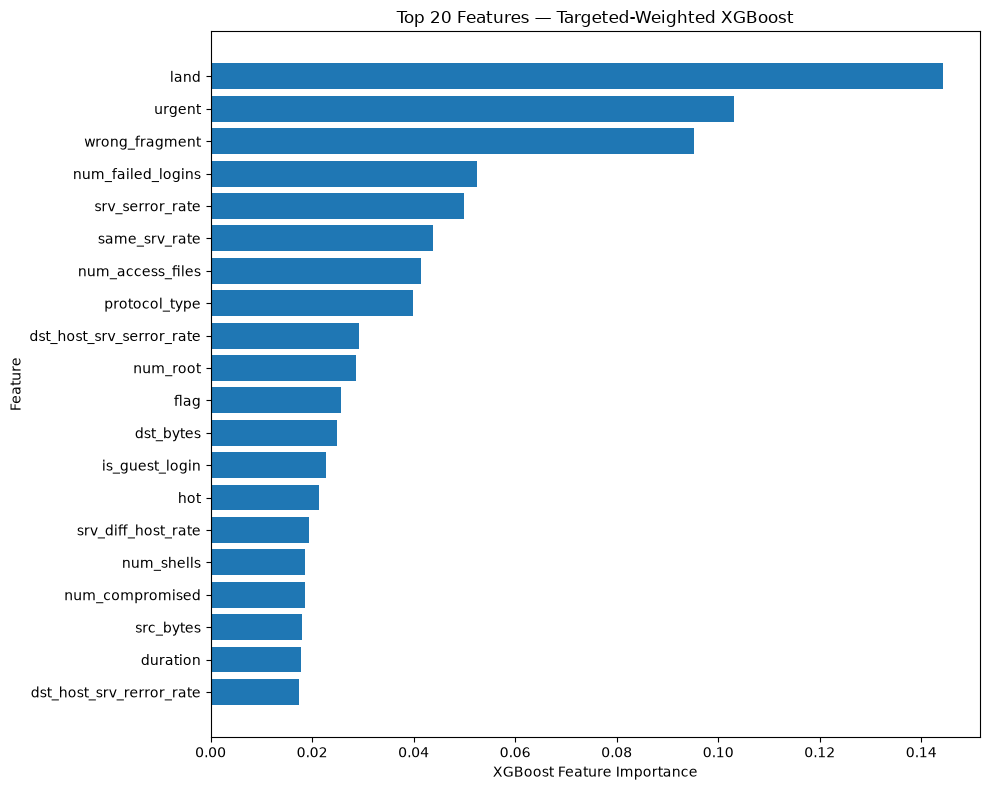


Saved feature importance files:
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_15_all_feature_importance.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_15_top20_feature_importance.csv
d:\smart-cybersecurity-ml\results\phase10\phase10_step10_15_top20_feature_importance.png

Step 10.15 completed.


In [25]:

# ============================================================
# PHASE 10 — STEP 10.15: TARGETED MODEL FEATURE IMPORTANCE
# ============================================================

from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load targeted XGBoost candidate
# ------------------------------------------------------------

model_path = (
    MODEL_DIR / "phase10_targeted_weight_xgboost_candidate.pkl"
)

if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path}")

model = joblib.load(model_path)

if not hasattr(model, "feature_importances_"):
    raise TypeError(
        "The loaded model does not expose feature_importances_."
    )

# ------------------------------------------------------------
# 2. Load feature names
# ------------------------------------------------------------

feature_path = (
    PROJECT_ROOT / "data" / "processed" / "X_train_encoded.csv"
)

if not feature_path.exists():
    raise FileNotFoundError(f"Feature file not found: {feature_path}")

X_features = pd.read_csv(feature_path)
feature_names = X_features.columns.tolist()
importance_values = model.feature_importances_

if len(feature_names) != len(importance_values):
    raise ValueError(
        "Feature-name count does not match model importance count. "
        "Verify the training feature order."
    )

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
}).sort_values("importance", ascending=False)

# ------------------------------------------------------------
# 3. Display and save top 20 features
# ------------------------------------------------------------

top_20 = importance_df.head(20).copy()

print("TOP 20 MOST IMPORTANT FEATURES")
display(top_20.round(6))

importance_df.to_csv(
    RESULTS_DIR / "phase10_step10_15_all_feature_importance.csv",
    index=False
)

top_20.to_csv(
    RESULTS_DIR / "phase10_step10_15_top20_feature_importance.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Plot top 20 features
# ------------------------------------------------------------

plot_df = top_20.sort_values("importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features — Targeted-Weighted XGBoost")
plt.tight_layout()

plot_path = (
    RESULTS_DIR / "phase10_step10_15_top20_feature_importance.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved feature importance files:")
print(RESULTS_DIR / "phase10_step10_15_all_feature_importance.csv")
print(RESULTS_DIR / "phase10_step10_15_top20_feature_importance.csv")
print(plot_path)

print("\nStep 10.15 completed.")


Step 10.17 — Verify the best model for all remaining attacks

In [26]:

# ============================================================
# PHASE 10 — STEP 10.17: BEST MODEL VERIFICATION
# Exclude rootkit and multihop from aggregate macro metrics
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "phase10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load test data
# ------------------------------------------------------------

X_test = pd.read_csv(DATA_DIR / "X_test_encoded.csv")
X_test_scaled = np.load(DATA_DIR / "X_test_scaled.npy")
y_test = np.load(DATA_DIR / "y_test_encoded.npy")

target_encoder = joblib.load(DATA_DIR / "target_encoder.pkl")

# ------------------------------------------------------------
# 2. Load all three candidate models
# ------------------------------------------------------------

original_model = joblib.load(
    MODEL_DIR / "final_xgboost_model.pkl"
)

standard_model = joblib.load(
    MODEL_DIR / "phase9_selected_xgboost_candidate.pkl"
)

targeted_model = joblib.load(
    MODEL_DIR / "phase10_targeted_weight_xgboost_candidate.pkl"
)

# ------------------------------------------------------------
# 3. Generate predictions using each model's input format
# ------------------------------------------------------------

predictions_by_model = {
    "Original XGBoost": original_model.predict(X_test_scaled),
    "Standard Weighted XGBoost": standard_model.predict(X_test),
    "Targeted Weighted XGBoost": targeted_model.predict(X_test)
}

# ------------------------------------------------------------
# 4. Calculate metrics for all classes
# ------------------------------------------------------------

class_names = list(target_encoder.classes_)
all_labels = np.arange(len(class_names))

excluded_attacks = {"rootkit", "multihop"}
included_labels = [
    i for i, name in enumerate(class_names)
    if name not in excluded_attacks
]

summary_rows = []
class_rows = []

for model_name, predictions in predictions_by_model.items():

    if len(predictions) != len(y_test):
        raise ValueError(
            f"{model_name}: prediction count does not match test labels."
        )

    report = classification_report(
        y_test,
        predictions,
        labels=all_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    # Macro metrics over all classes except rootkit and multihop.
    # Predictions remain evaluated against the complete test set.
    macro_precision = np.mean([
        report[class_names[i]]["precision"]
        for i in included_labels
    ])

    macro_recall = np.mean([
        report[class_names[i]]["recall"]
        for i in included_labels
    ])

    macro_f1 = np.mean([
        report[class_names[i]]["f1-score"]
        for i in included_labels
    ])

    summary_rows.append({
        "model": model_name,
        "accuracy_all_test_samples": accuracy_score(y_test, predictions),
        "balanced_accuracy_all_classes": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_precision_excluding_two": macro_precision,
        "macro_recall_excluding_two": macro_recall,
        "macro_f1_excluding_two": macro_f1
    })

    for attack in class_names:
        if attack in excluded_attacks:
            continue

        values = report[attack]

        class_rows.append({
            "attack": attack,
            "model": model_name,
            "precision": values["precision"],
            "recall": values["recall"],
            "f1": values["f1-score"],
            "support": int(values["support"])
        })

summary_df = pd.DataFrame(summary_rows).sort_values(
    "macro_f1_excluding_two", ascending=False
)

class_metrics_df = pd.DataFrame(class_rows)

# ------------------------------------------------------------
# 5. Identify the best F1 model for each remaining attack
# ------------------------------------------------------------

best_indices = class_metrics_df.groupby("attack")["f1"].idxmax()

best_per_attack = class_metrics_df.loc[best_indices].copy()
best_per_attack = best_per_attack.rename(
    columns={
        "model": "best_model_by_f1",
        "f1": "best_f1",
        "precision": "best_precision",
        "recall": "best_recall"
    }
)

best_per_attack = best_per_attack.sort_values("attack")

# Identify ties where multiple models have the same best F1.
best_f1_by_attack = class_metrics_df.groupby("attack")["f1"].max()

tie_rows = []

for attack, best_f1 in best_f1_by_attack.items():
    tied_models = class_metrics_df[
        (class_metrics_df["attack"] == attack)
        & np.isclose(class_metrics_df["f1"], best_f1)
    ]["model"].tolist()

    tie_rows.append({
        "attack": attack,
        "best_f1": best_f1,
        "best_models": " | ".join(tied_models),
        "number_of_tied_models": len(tied_models)
    })

ties_df = pd.DataFrame(tie_rows)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("OVERALL COMPARISON — ROOTKIT AND MULTIHOP EXCLUDED FROM MACRO SCORES")
display(summary_df.round(6))

print("\nBEST MODEL FOR EACH REMAINING ATTACK — BY F1")
display(best_per_attack.round(4))

print("\nPER-ATTACK F1 TIES")
display(ties_df.round(4))

# ------------------------------------------------------------
# 7. Save all comparison files
# ------------------------------------------------------------

summary_df.to_csv(
    RESULTS_DIR / "phase10_step10_17_overall_model_comparison.csv",
    index=False
)

class_metrics_df.to_csv(
    RESULTS_DIR / "phase10_step10_17_all_remaining_class_metrics.csv",
    index=False
)

best_per_attack.to_csv(
    RESULTS_DIR / "phase10_step10_17_best_model_per_attack.csv",
    index=False
)

ties_df.to_csv(
    RESULTS_DIR / "phase10_step10_17_best_model_ties.csv",
    index=False
)

print("\nSaved all Step 10.17 comparison files.")
print("Step 10.17 completed.")


OVERALL COMPARISON — ROOTKIT AND MULTIHOP EXCLUDED FROM MACRO SCORES


,model,accuracy_all_test_samples,balanced_accuracy_all_classes,macro_precision_excluding_two,macro_recall_excluding_two,macro_f1_excluding_two
2,Targeted Weighted XGBoost,0.996498,0.867294,0.893549,0.934009,0.902639
0,Original XGBoost,0.997542,0.840815,0.909132,0.905493,0.901358
1,Standard Weighted XGBoost,0.996397,0.865237,0.888182,0.931794,0.898787



BEST MODEL FOR EACH REMAINING ATTACK — BY F1


,attack,best_model_by_f1,best_precision,best_recall,best_f1,support
0,apache2,Original XGBoost,1.0000,1.0000,1.0000,46
1,back,Original XGBoost,1.0000,1.0000,1.0000,237
2,buffer_overflow,Original XGBoost,1.0000,0.8889,0.9412,9
29,ftp_write,Standard Weighted XGBoost,1.0000,0.5000,0.6667,2
56,guess_passwd,Targeted Weighted XGBoost,0.9894,1.0000,0.9947,93
5,httptunnel,Original XGBoost,1.0000,1.0000,1.0000,8
6,imap,Original XGBoost,1.0000,1.0000,1.0000,2
7,ipsweep,Original XGBoost,0.9951,0.9988,0.9969,816
8,land,Original XGBoost,0.5714,1.0000,0.7273,4
9,loadmodule,Original XGBoost,1.0000,0.5000,0.6667,2



PER-ATTACK F1 TIES


,attack,best_f1,best_models,number_of_tied_models
0,apache2,1.0000,Original XGBoost | Standard Weighted XGBoost |...,3
1,back,1.0000,Original XGBoost | Standard Weighted XGBoost |...,3
2,buffer_overflow,0.9412,Original XGBoost,1
3,ftp_write,0.6667,Standard Weighted XGBoost | Targeted Weighted ...,2
4,guess_passwd,0.9947,Targeted Weighted XGBoost,1
5,httptunnel,1.0000,Original XGBoost | Standard Weighted XGBoost |...,3
6,imap,1.0000,Original XGBoost | Standard Weighted XGBoost |...,3
7,ipsweep,0.9969,Original XGBoost,1
8,land,0.7273,Original XGBoost | Standard Weighted XGBoost |...,3
9,loadmodule,0.6667,Original XGBoost,1



Saved all Step 10.17 comparison files.
Step 10.17 completed.
